# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot regional SIC ice edge in 1950, 2000, 2050 to see where maximum baroclinicity is changing

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Load data
- regional, monthly data by decade

### Get grid data

In [2]:
# load grid files for plotting

dir_grid = '/glade/u/home/duvivier/masks/'
file_in = 'POP_tx0.1v3_grid.nc'
ds_grid = xr.open_mfdataset(dir_grid+file_in, decode_times=False)    

# clip global data to match other files - do in two steps because that's how I originally clipped data
# Step 1: clip to full Arctic Region
ds_grid_sub = ds_grid.isel(nlat=slice(1750,2400))
# Step 2: clip Arctic Region to Pacific sector only
ds_grid_sub = ds_grid_sub.isel(nlon=slice(2500,3250))

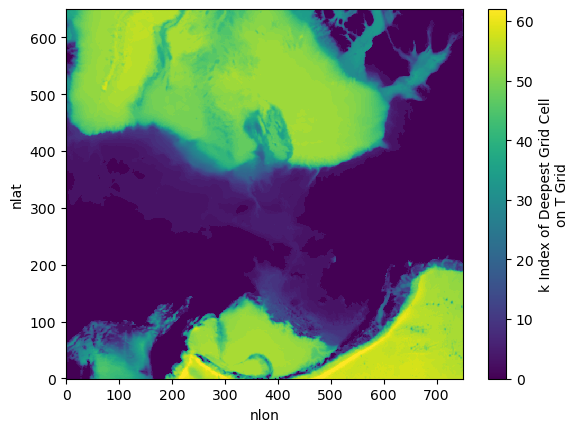

In [3]:
ds_grid_sub.KMT.plot()

In [4]:
# grab lat and lon data
lat2d = ds_grid_sub.TLAT
lon2d = ds_grid_sub.TLONG

### Get SIC data
- monthly data by decade

In [5]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_composites/'

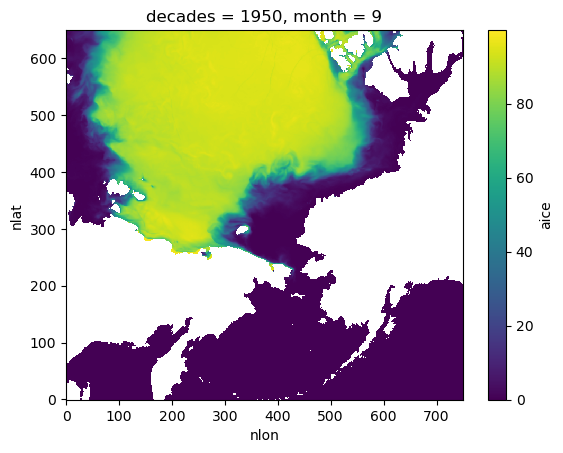

In [6]:
# Load SST data for larger area than only training area - set file name
var_in = 'aice'
fin = var_in+'_monthly_autumn_decadal_alaska_cam_grid.nc'

# load data
ds = xr.open_dataset(dir_in+fin)

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep only the variable of interest
ds_sic = ds[var_in]

# rename coordinates to those used in grid file
ds_sic = ds_sic.rename({'nj' :'nlat', 'ni': 'nlon'})

ds_sic.isel(ensemble=0,decades=0,month=0).plot()

## Get monthly ensemble mean data for just three decades
- Get decades: 1950, 2000, 2050
- Subset for months then get ensemble means over ensemble and all three years in a decade

### SIC

In [7]:
# SIC
sic_1950 = ds_sic.sel(decades = 1950)
sic_2000 = ds_sic.sel(decades = 2000)
sic_2050 = ds_sic.sel(decades = 2050)

In [8]:
# averages
# 1950
sic_1950_sep_avg = sic_1950.where(sic_1950.month == 9, drop=True).mean(dim=['ensemble', 'month'])
sic_1950_oct_avg = sic_1950.where(sic_1950.month == 10, drop=True).mean(dim=['ensemble', 'month'])
sic_1950_nov_avg = sic_1950.where(sic_1950.month == 11, drop=True).mean(dim=['ensemble', 'month'])
sic_1950_dec_avg = sic_1950.where(sic_1950.month == 12, drop=True).mean(dim=['ensemble', 'month'])

# 2000
sic_2000_sep_avg = sic_2000.where(sic_2000.month == 9, drop=True).mean(dim=['ensemble', 'month'])
sic_2000_oct_avg = sic_2000.where(sic_2000.month == 10, drop=True).mean(dim=['ensemble', 'month'])
sic_2000_nov_avg = sic_2000.where(sic_2000.month == 11, drop=True).mean(dim=['ensemble', 'month'])
sic_2000_dec_avg = sic_2000.where(sic_2000.month == 12, drop=True).mean(dim=['ensemble', 'month'])

# 2050
sic_2050_sep_avg = sic_2050.where(sic_2050.month == 9, drop=True).mean(dim=['ensemble', 'month'])
sic_2050_oct_avg = sic_2050.where(sic_2050.month == 10, drop=True).mean(dim=['ensemble', 'month'])
sic_2050_nov_avg = sic_2050.where(sic_2050.month == 11, drop=True).mean(dim=['ensemble', 'month'])
sic_2050_dec_avg = sic_2050.where(sic_2050.month == 12, drop=True).mean(dim=['ensemble', 'month'])

In [9]:
# standard deviation
# 1950
sic_1950_sep_std = sic_1950.where(sic_1950.month == 9, drop=True).std(dim=['ensemble', 'month'])
sic_1950_oct_std = sic_1950.where(sic_1950.month == 10, drop=True).std(dim=['ensemble', 'month'])
sic_1950_nov_std = sic_1950.where(sic_1950.month == 11, drop=True).std(dim=['ensemble', 'month'])
sic_1950_dec_std = sic_1950.where(sic_1950.month == 12, drop=True).std(dim=['ensemble', 'month'])

# 2000
sic_2000_sep_std = sic_2000.where(sic_2000.month == 9, drop=True).std(dim=['ensemble', 'month'])
sic_2000_oct_std = sic_2000.where(sic_2000.month == 10, drop=True).std(dim=['ensemble', 'month'])
sic_2000_nov_std = sic_2000.where(sic_2000.month == 11, drop=True).std(dim=['ensemble', 'month'])
sic_2000_dec_std = sic_2000.where(sic_2000.month == 12, drop=True).std(dim=['ensemble', 'month'])

# 2050
sic_2050_sep_std = sic_2050.where(sic_2050.month == 9, drop=True).std(dim=['ensemble', 'month'])
sic_2050_oct_std = sic_2050.where(sic_2050.month == 10, drop=True).std(dim=['ensemble', 'month'])
sic_2050_nov_std = sic_2050.where(sic_2050.month == 11, drop=True).std(dim=['ensemble', 'month'])
sic_2050_dec_std = sic_2050.where(sic_2050.month == 12, drop=True).std(dim=['ensemble', 'month'])

/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slic

## Plot Maps by decade and month to compare

In [10]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [25]:
# set lat/lon bounds
lat_max = 79
lat_min = 53
lon_max = 205
lon_min = 175
lon_avg = 191.625

In [26]:
# lats and lons for a transect line
lons = [lon_avg, lon_avg]
lats = [50, 90]

In [27]:
## set colors and levels for sst
cmap_in = cmocean.cm.ice
vmin_in = 0
vmax_in = 100
levels_in = np.arange(0,105,5)
ticks_in = [0,10,20,30,40,50,60,70,80,90,100]
units_in = '%'
var_in = 'SIC'

In [28]:
# set ice edge line for overlay contour plot
levels_ice = [15,100]

### Create SIC fill plots

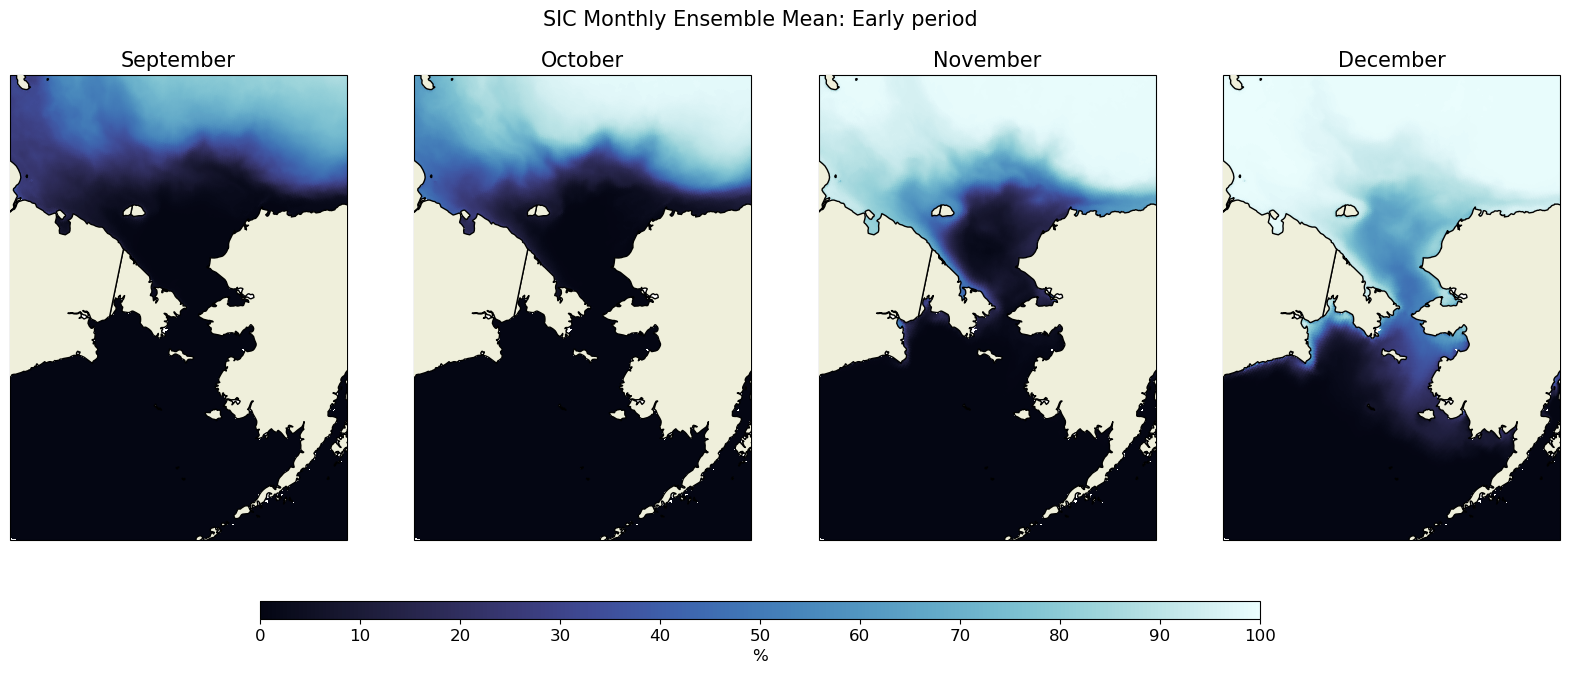

In [29]:
### Choose year and data to plot
yyyy = '1950'

# set data to plot
sep_data = sic_1950_sep_avg
oct_data = sic_1950_oct_avg
nov_data = sic_1950_nov_avg
dec_data = sic_1950_dec_avg

#### 
# create figure
fig = plt.figure(figsize=(20,7))
fout = 'supp_decadal_'+var_in+'_regional_avg_'+yyyy

# Make subplots - note it's nrow x ncol x index (starting upper left)
### Sept
ax = fig.add_subplot(1,4,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, sep_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('September',fontsize=15)

### Oct
ax = fig.add_subplot(1,4,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, oct_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('October',fontsize=15)

### Nov
ax = fig.add_subplot(1,4,3, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, nov_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('November',fontsize=15)

### Dec
ax = fig.add_subplot(1,4,4, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = pcm = ax.pcolormesh(lon2d, lat2d, dec_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('December',fontsize=15)

# Finalize figure and save
#add title
fig.suptitle(var_in+' Monthly Ensemble Mean: Early period',fontsize=15, y=0.92)

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.05,0.5,0.025]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_in[:],orientation='horizontal')
cbar.ax.set_xticklabels(list(ticks_in))
cbar.ax.tick_params(labelsize=12)
cbar.set_label(units_in, fontsize=12)

# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

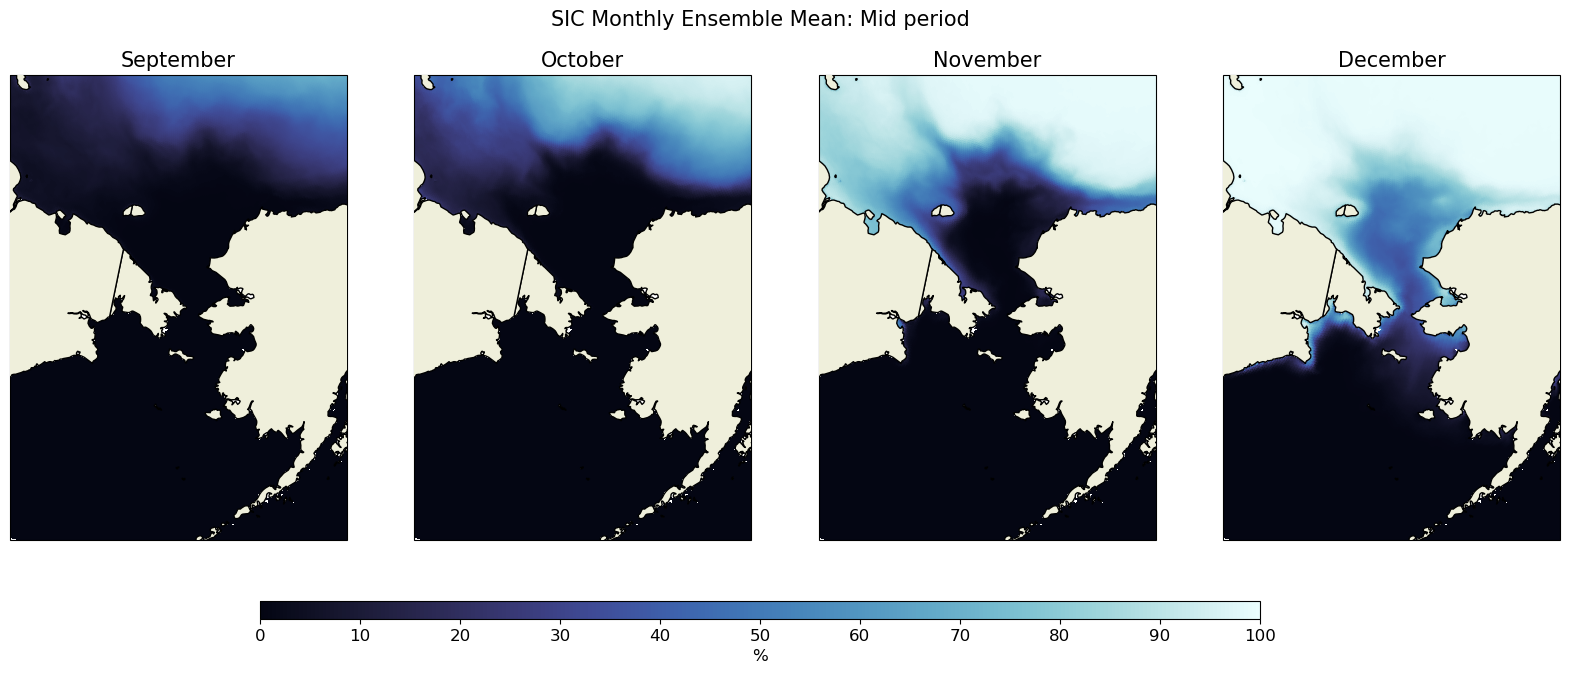

In [30]:
### Choose year and data to plot
yyyy = '2000'

# set data to plot
sep_data = sic_2000_sep_avg
oct_data = sic_2000_oct_avg
nov_data = sic_2000_nov_avg
dec_data = sic_2000_dec_avg

#### 
# create figure
fig = plt.figure(figsize=(20,7))
fout = 'supp_decadal_'+var_in+'_regional_avg_'+yyyy

# Make subplots - note it's nrow x ncol x index (starting upper left)
### Sept
ax = fig.add_subplot(1,4,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, sep_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('September',fontsize=15)

### Oct
ax = fig.add_subplot(1,4,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, oct_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('October',fontsize=15)

### Nov
ax = fig.add_subplot(1,4,3, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, nov_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('November',fontsize=15)

### Dec
ax = fig.add_subplot(1,4,4, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = pcm = ax.pcolormesh(lon2d, lat2d, dec_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('December',fontsize=15)

# Finalize figure and save
#add title
fig.suptitle(var_in+' Monthly Ensemble Mean: Mid period',fontsize=15, y=0.92)

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.05,0.5,0.025]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_in[:],orientation='horizontal')
cbar.ax.set_xticklabels(list(ticks_in))
cbar.ax.tick_params(labelsize=12)
cbar.set_label(units_in, fontsize=12)

# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

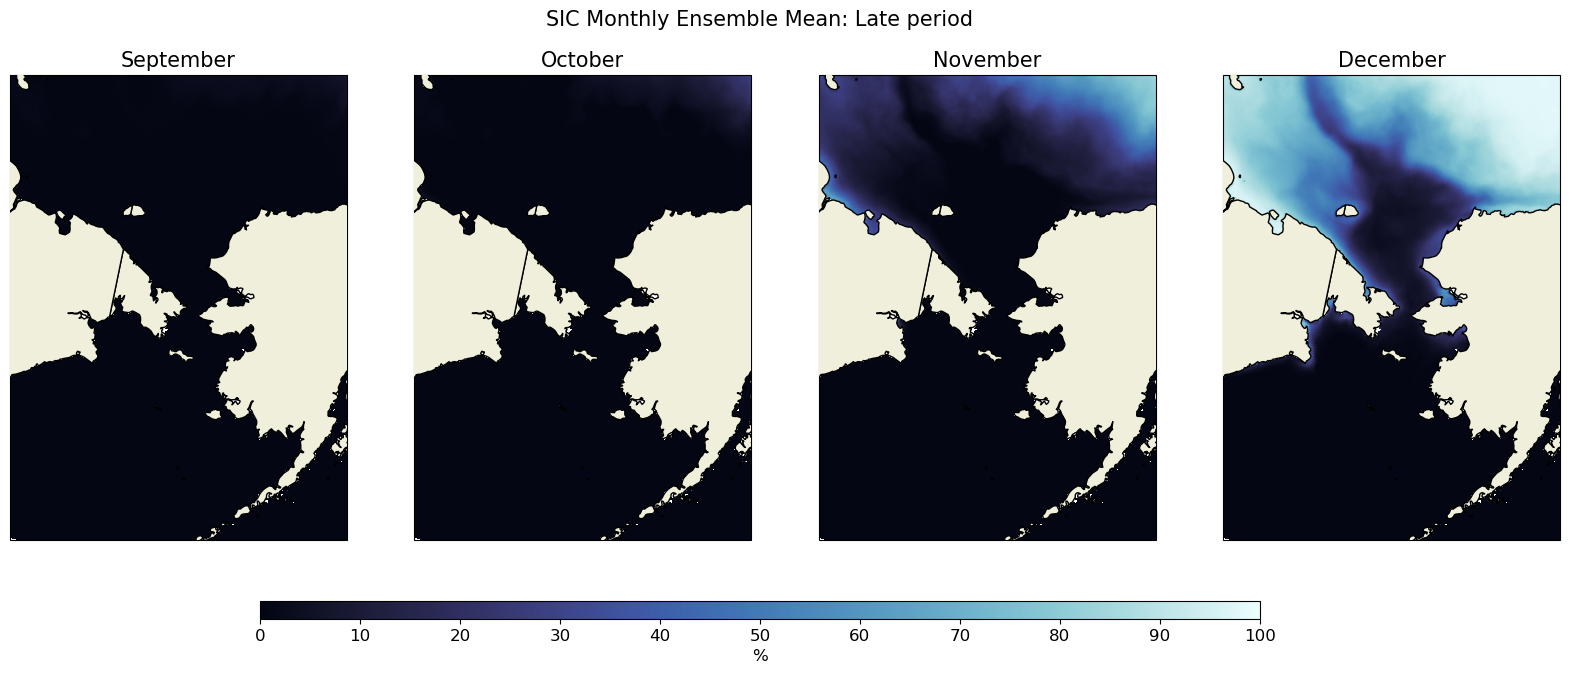

In [31]:
### Choose year and data to plot
yyyy = '2050'

# set data to plot
sep_data = sic_2050_sep_avg
oct_data = sic_2050_oct_avg
nov_data = sic_2050_nov_avg
dec_data = sic_2050_dec_avg

#### 
# create figure
fig = plt.figure(figsize=(20,7))
fout = 'supp_decadal_'+var_in+'_regional_avg_'+yyyy

# Make subplots - note it's nrow x ncol x index (starting upper left)
### Sept
ax = fig.add_subplot(1,4,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, sep_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('September',fontsize=15)

### Oct
ax = fig.add_subplot(1,4,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, oct_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('October',fontsize=15)

### Nov
ax = fig.add_subplot(1,4,3, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon2d, lat2d, nov_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('November',fontsize=15)

### Dec
ax = fig.add_subplot(1,4,4, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = pcm = ax.pcolormesh(lon2d, lat2d, dec_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('December',fontsize=15)

# Finalize figure and save
#add title
fig.suptitle(var_in+' Monthly Ensemble Mean: Late period',fontsize=15, y=0.92)

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.05,0.5,0.025]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_in[:],orientation='horizontal')
cbar.ax.set_xticklabels(list(ticks_in))
cbar.ax.tick_params(labelsize=12)
cbar.set_label(units_in, fontsize=12)

# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)